# Interactive Time Series Analysis: ARIMA
In this notebook, we will visualize the exact data transformations required for an ARIMA model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Set plot styles
plt.style.use('seaborn-v0_8-darkgrid')

### 1. Generating the Dataset
We generate 5 years of monthly sales data. Notice how the values steadily increase over time, meaning the data is **Non-Stationary**.

,Sales
Date,
2020-01-31,5149.014246
2020-02-29,5009.368167
2020-03-31,5296.001477
2020-04-30,5609.451330
2020-05-31,5133.143818


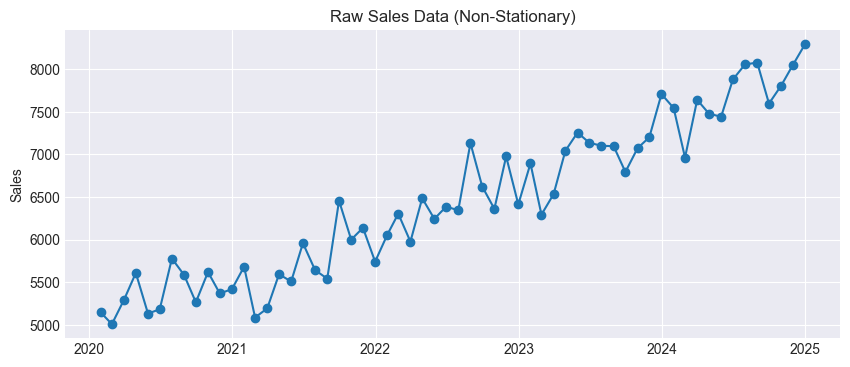

In [2]:
np.random.seed(42)
months = pd.date_range(start='2020-01-01', periods=60, freq='ME')

base_sales = 5000
trend = np.linspace(0, 3000, 60)
noise = np.random.normal(0, 300, 60)
sales = base_sales + trend + noise

df = pd.DataFrame({'Date': months, 'Sales': sales})
df.set_index('Date', inplace=True)

# Display the raw data (first 5 rows)
display(df.head())

plt.figure(figsize=(10, 4))
plt.plot(df.index, df['Sales'], marker='o')
plt.title('Raw Sales Data (Non-Stationary)')
plt.ylabel('Sales')
plt.show()

In [4]:
df.count()

Sales    60
dtype: int64

### 2. Testing for Stationarity
We use the **Augmented Dickey-Fuller (ADF) test**. If the p-value is greater than 0.05, it mathematically proves the data has a trend and needs to be transformed.

In [5]:
result = adfuller(df['Sales'])
print(f"ADF Statistic: {result[0]:.4f}")
print(f"p-value:       {result[1]:.4f}")
print("\nVerdict:       NOT Stationary" if result[1] > 0.05 else "Verdict: Stationary")

ADF Statistic: 1.2478
p-value:       0.9963

Verdict:       NOT Stationary


### 3. The Transformation: Differencing ('d')
ARIMA requires flat data. We transform the data by subtracting yesterday's sales from today's sales. This is **d=1**.
Watch how the chart completely flattens out around the zero line!

,Sales,Sales_Diff
Date,,
2020-01-31,5149.014246,NaN
2020-02-29,5009.368167,-139.646079
2020-03-31,5296.001477,286.633309
2020-04-30,5609.451330,313.449853
2020-05-31,5133.143818,-476.307512


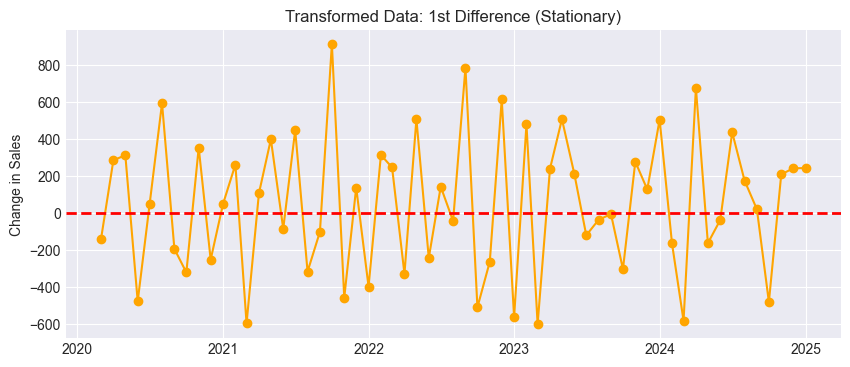

New p-value:   0.0000
Verdict:       STATIONARY!


In [6]:
# The Transformation Step
df['Sales_Diff'] = df['Sales'].diff()

display(df.head())

plt.figure(figsize=(10, 4))
plt.plot(df.index, df['Sales_Diff'], marker='o', color='orange')
plt.title('Transformed Data: 1st Difference (Stationary)')
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.ylabel('Change in Sales')
plt.show()

diff_result = adfuller(df['Sales_Diff'].dropna())
print(f"New p-value:   {diff_result[1]:.4f}")
print("Verdict:       STATIONARY!" if diff_result[1] < 0.05 else "Verdict: Still Not Stationary")

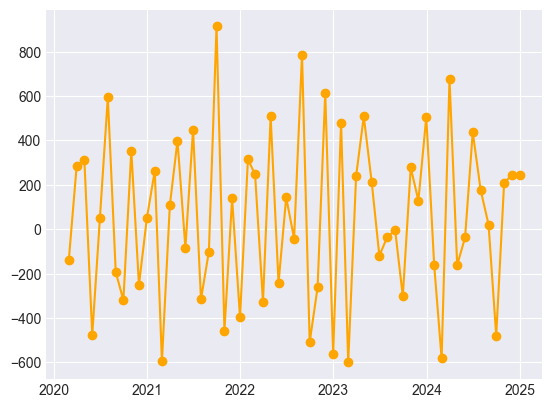

In [7]:
plt.plot(df.index, df['Sales_Diff'], marker='o', color='orange')

### 4. ACF and PACF Plots
These plots help us find the `p` and `q` parameters by looking at how past days correlate with today. We use the *differenced* data for these plots.

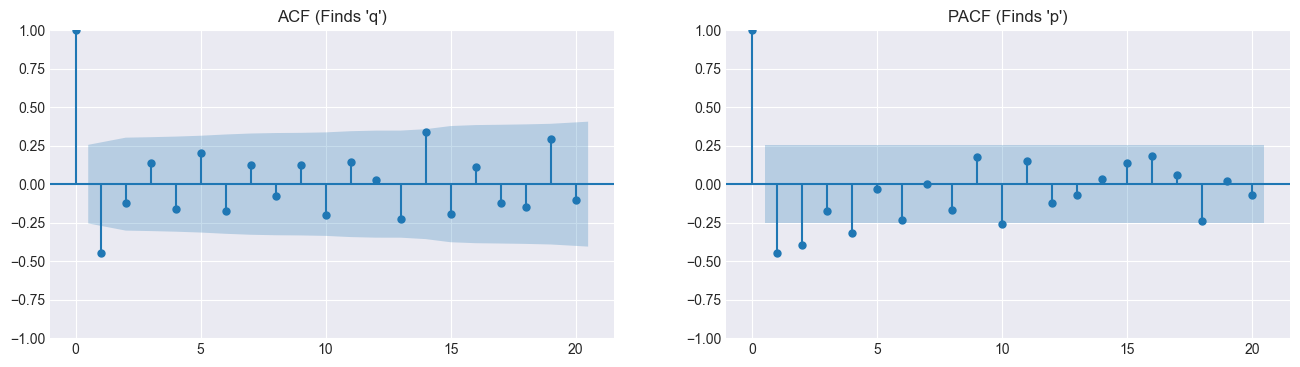

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(df['Sales_Diff'].dropna(), lags=20, ax=ax1)
ax1.set_title("ACF (Finds 'q')")
plot_pacf(df['Sales_Diff'].dropna(), lags=20, ax=ax2, method='ywm')
ax2.set_title("PACF (Finds 'p')")
plt.show()

### 5. Fitting ARIMA and Forecasting
Now we apply ARIMA(1, 1, 1). 

**Important:** Notice how we pass the **original raw data** into the model, but we set `order=(1, 1, 1)`. The `1` in the middle tells ARIMA to apply that differencing transformation automatically under the hood!

c:\Users\DELL\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


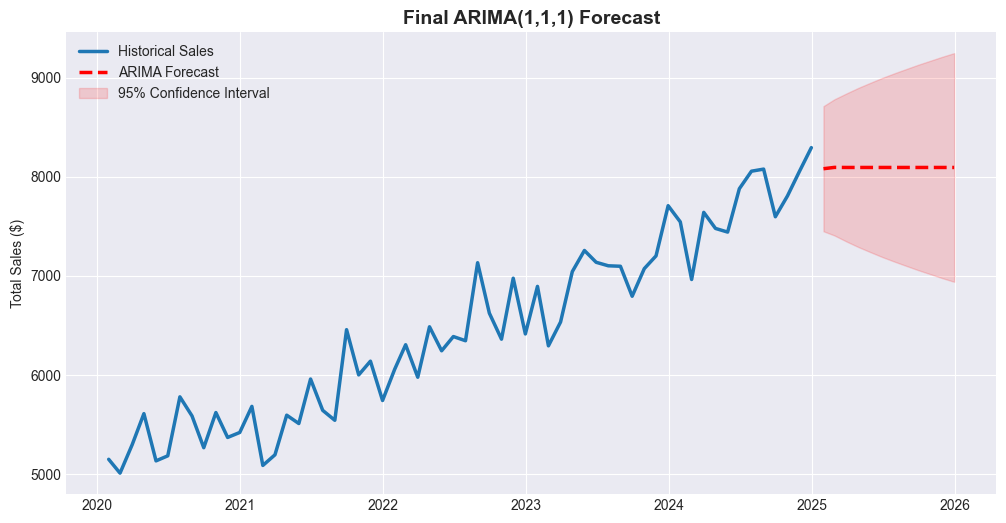

In [9]:
# Pass original data, but tell it to difference it once (d=1)
model = ARIMA(df['Sales'], order=(1, 1, 1))
fitted_model = model.fit()

# Forecast 12 months ahead
forecast = fitted_model.get_forecast(steps=12)
forecast_mean = forecast.predicted_mean
conf_int = forecast.conf_int()

plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Sales'], label='Historical Sales', linewidth=2.5)
plt.plot(forecast_mean.index, forecast_mean, color='red', linestyle='--', label='ARIMA Forecast', linewidth=2.5)
plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='red', alpha=0.15, label='95% Confidence Interval')
plt.title('Final ARIMA(1,1,1) Forecast', fontsize=14, fontweight='bold')
plt.ylabel('Total Sales ($)')
plt.legend()
plt.show()